# # Подготовка ECG-данных и референсной разметки

## Цель

Подготовить запись из MIT-BIH Arrhythmia Database для последующего
исследования алгоритмов обнаружения QRS-комплексов и оценки качества ECG.

## Задачи

1. Загрузить одноканальную ECG и экспертные аннотации сердечных сокращений.
2. Выделить из набора аннотаций только аннотации сокращений.
3. Визуализировать ECG совместно с референсной разметкой.
4. Рассчитать RR-интервалы и мгновенную частоту сердечных сокращений.
5. Привести ECG к частоте дискретизации 250 Гц.
6. Пересчитать положения аннотаций после изменения частоты дискретизации.
7. Проверить сохранение временного соответствия ECG и разметки.

На данном этапе автоматическое обнаружение QRS не выполняется.
Используется только экспертная разметка базы данных.

In [1]:
%pip install wfdb numpy scipy pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 63.6 MB/s  0:00:00s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 65.1 MB/s  0:00:00s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 62.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 61.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 52.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 57.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 44.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 68.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 42.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20/20 [wfdb]m━━━ 18/20 [aiohttp]ib]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from pathlib import Path
from fractions import Fraction
from scipy.signal import resample_poly

In [3]:
RECORD_NAME = "100"
DATABASE = "mitdb"

CHANNEL = 0
TARGET_FS = 250

PLOT_START_SEC = 10
PLOT_DURATION_SEC = 10

In [4]:
record = wfdb.rdrecord(
    RECORD_NAME,
    pn_dir=DATABASE,
    channels=[CHANNEL]
)

ecg = record.p_signal[:, 0].astype(np.float64)
fs_original = float(record.fs)

In [5]:
print(f"Record: {RECORD_NAME}")
print(f"Sampling frequency: {fs_original} Hz")
print(f"Number of samples: {len(ecg)}")
print(f"Duration: {len(ecg) / fs_original:.1f} s")
print(f"Signal name: {record.sig_name}")
print(f"Units: {record.units}")

Record: 100
Sampling frequency: 360.0 Hz
Number of samples: 650000
Duration: 1805.6 s
Signal name: ['MLII']
Units: ['mV']


In [6]:
annotation = wfdb.rdann(
    RECORD_NAME,
    "atr",
    pn_dir=DATABASE
)

In [7]:
for sample, symbol in zip(
    annotation.sample[:20],
    annotation.symbol[:20]
):
    print(
        f"sample={sample:6d} | "
        f"time={sample / fs_original:8.3f} s | "
        f"symbol={symbol}"
    )

sample=    18 | time=   0.050 s | symbol=+
sample=    77 | time=   0.214 s | symbol=N
sample=   370 | time=   1.028 s | symbol=N
sample=   662 | time=   1.839 s | symbol=N
sample=   946 | time=   2.628 s | symbol=N
sample=  1231 | time=   3.419 s | symbol=N
sample=  1515 | time=   4.208 s | symbol=N
sample=  1809 | time=   5.025 s | symbol=N
sample=  2044 | time=   5.678 s | symbol=A
sample=  2402 | time=   6.672 s | symbol=N
sample=  2706 | time=   7.517 s | symbol=N
sample=  2998 | time=   8.328 s | symbol=N
sample=  3282 | time=   9.117 s | symbol=N
sample=  3560 | time=   9.889 s | symbol=N
sample=  3862 | time=  10.728 s | symbol=N
sample=  4170 | time=  11.583 s | symbol=N
sample=  4466 | time=  12.406 s | symbol=N
sample=  4764 | time=  13.233 s | symbol=N
sample=  5060 | time=  14.056 s | symbol=N
sample=  5346 | time=  14.850 s | symbol=N


In [8]:
BEAT_SYMBOLS = {
    "N",  # normal beat
    "L",  # left bundle branch block beat
    "R",  # right bundle branch block beat
    "B",  # bundle branch block beat
    "A",  # atrial premature beat
    "a",  # aberrated atrial premature beat
    "J",  # nodal premature beat
    "S",  # supraventricular premature beat
    "V",  # premature ventricular contraction
    "r",  # R-on-T PVC
    "F",  # fusion of ventricular and normal beat
    "e",  # atrial escape beat
    "j",  # nodal escape beat
    "n",  # supraventricular escape beat
    "E",  # ventricular escape beat
    "/",  # paced beat
    "f",  # fusion of paced and normal beat
    "Q",  # unclassifiable beat
    "?",  # beat not classified
}

In [9]:
annotation_symbols = np.asarray(annotation.symbol)

beat_mask = np.array([
    symbol in BEAT_SYMBOLS
    for symbol in annotation_symbols
])

beat_samples = annotation.sample[beat_mask]
beat_symbols = annotation_symbols[beat_mask]

In [10]:
print("Всего аннотаций:", len(annotation.sample))
print("Аннотаций сокращений:", len(beat_samples))

print("\nПервые сокращения:")
for sample, symbol in zip(
    beat_samples[:10],
    beat_symbols[:10]
):
    print(
        f"{sample:6d} | "
        f"{sample / fs_original:8.3f} s | "
        f"{symbol}"
    )

Всего аннотаций: 2274
Аннотаций сокращений: 2273

Первые сокращения:
    77 |    0.214 s | N
   370 |    1.028 s | N
   662 |    1.839 s | N
   946 |    2.628 s | N
  1231 |    3.419 s | N
  1515 |    4.208 s | N
  1809 |    5.025 s | N
  2044 |    5.678 s | A
  2402 |    6.672 s | N
  2706 |    7.517 s | N


In [11]:
def plot_ecg_with_beats(
    signal,
    fs,
    beat_samples,
    beat_symbols,
    start_sec=0,
    duration_sec=10,
    title="ECG"
):
    start_sample = int(round(start_sec * fs))
    end_sample = int(round((start_sec + duration_sec) * fs))

    end_sample = min(end_sample, len(signal))

    time = np.arange(start_sample, end_sample) / fs

    mask = (
        (beat_samples >= start_sample)
        & (beat_samples < end_sample)
    )

    samples_in_window = beat_samples[mask]
    symbols_in_window = beat_symbols[mask]

    plt.figure(figsize=(15, 5))

    plt.plot(
        time,
        signal[start_sample:end_sample],
        linewidth=1
    )

    plt.scatter(
        samples_in_window / fs,
        signal[samples_in_window],
        marker="x",
        s=50
    )

    for sample, symbol in zip(
        samples_in_window,
        symbols_in_window
    ):
        plt.text(
            sample / fs,
            signal[sample],
            symbol,
            fontsize=9,
            ha="center",
            va="bottom"
        )

    plt.xlabel("Time, s")
    plt.ylabel("ECG amplitude")
    plt.title(title)

    plt.grid(alpha=0.3)
    plt.show()

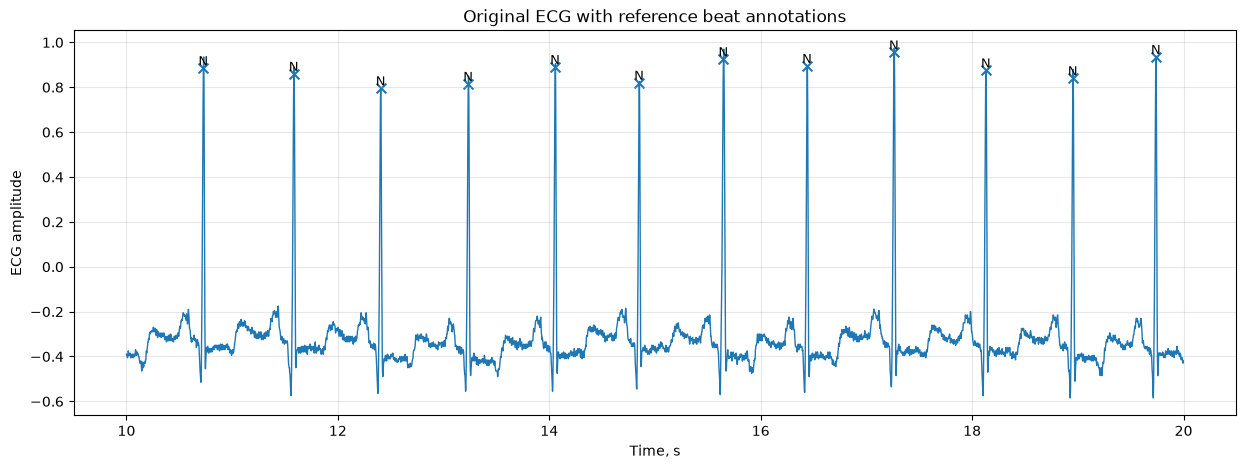

In [12]:
plot_ecg_with_beats(
    ecg,
    fs_original,
    beat_samples,
    beat_symbols,
    start_sec=PLOT_START_SEC,
    duration_sec=PLOT_DURATION_SEC,
    title="Original ECG with reference beat annotations"
)

In [13]:
beats_df = pd.DataFrame({
    "sample": beat_samples,
    "time_s": beat_samples / fs_original,
    "symbol": beat_symbols
})

beats_df.head(10)

,sample,time_s,symbol
0,77,0.213889,N
1,370,1.027778,N
2,662,1.838889,N
3,946,2.627778,N
4,1231,3.419444,N
5,1515,4.208333,N
6,1809,5.025000,N
7,2044,5.677778,A
8,2402,6.672222,N
9,2706,7.516667,N


In [14]:
beats_df["RR_ms"] = (
    beats_df["time_s"].diff() * 1000
)

In [15]:
beats_df["HR_bpm"] = (
    60000 / beats_df["RR_ms"]
)

In [16]:
beats_df.head(20)

,sample,time_s,symbol,RR_ms,HR_bpm
0,77,0.213889,N,NaN,NaN
1,370,1.027778,N,813.888889,73.720137
2,662,1.838889,N,811.111111,73.972603
3,946,2.627778,N,788.888889,76.056338
4,1231,3.419444,N,791.666667,75.789474
5,1515,4.208333,N,788.888889,76.056338
6,1809,5.025000,N,816.666667,73.469388
7,2044,5.677778,A,652.777778,91.914894
8,2402,6.672222,N,994.444444,60.335196
9,2706,7.516667,N,844.444444,71.052632


In [17]:
beats_df["symbol"].value_counts()

symbol
N    2239
A      33
V       1
Name: count, dtype: int64

In [18]:
beat_counts = beats_df["symbol"].value_counts()

beat_percent = (
    beat_counts
    / beat_counts.sum()
    * 100
)

pd.DataFrame({
    "count": beat_counts,
    "percent": beat_percent
})

,count,percent
symbol,,
N,2239,98.504179
A,33,1.451826
V,1,0.043995


In [19]:
assert ecg.ndim == 1

assert len(beat_samples) == len(beat_symbols)

assert np.all(
    np.diff(beat_samples) > 0
)

assert np.all(
    beat_samples >= 0
)

assert np.all(
    beat_samples < len(ecg)
)

print("Basic checks passed.")

Basic checks passed.


In [20]:
ratio = Fraction(
    TARGET_FS,
    int(round(fs_original))
)

up = ratio.numerator
down = ratio.denominator

print(f"Resampling ratio: {up}/{down}")

Resampling ratio: 25/36


In [21]:
ecg_250 = resample_poly(
    ecg,
    up,
    down
)

In [22]:
print("Original samples:", len(ecg))
print("Resampled samples:", len(ecg_250))

print(
    "Original duration:",
    len(ecg) / fs_original
)

print(
    "Resampled duration:",
    len(ecg_250) / TARGET_FS
)

Original samples: 650000
Resampled samples: 451389
Original duration: 1805.5555555555557
Resampled duration: 1805.556


In [23]:
beat_times_original = (
    beat_samples / fs_original
)

beat_samples_250 = np.rint(
    beat_times_original * TARGET_FS
).astype(int)

In [24]:
valid_mask = (
    beat_samples_250 < len(ecg_250)
)

beat_samples_250 = beat_samples_250[valid_mask]
beat_symbols_250 = beat_symbols[valid_mask]

beat_times_original = beat_times_original[valid_mask]

In [25]:
beat_times_250 = (
    beat_samples_250 / TARGET_FS
)

time_error_ms = (
    beat_times_250
    - beat_times_original
) * 1000

In [26]:
print(
    "Maximum annotation time error:",
    np.max(np.abs(time_error_ms)),
    "ms"
)

print(
    "Mean absolute annotation time error:",
    np.mean(np.abs(time_error_ms)),
    "ms"
)

Maximum annotation time error: 2.00000000018008 ms
Mean absolute annotation time error: 0.9890502028627759 ms


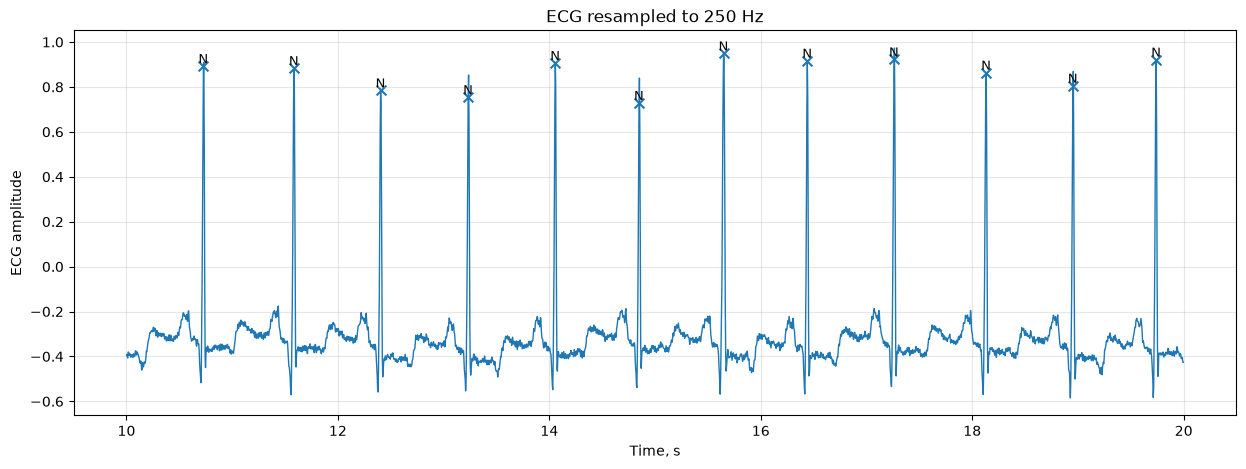

In [27]:
plot_ecg_with_beats(
    ecg_250,
    TARGET_FS,
    beat_samples_250,
    beat_symbols_250,
    start_sec=PLOT_START_SEC,
    duration_sec=PLOT_DURATION_SEC,
    title="ECG resampled to 250 Hz"
)

In [28]:
rr_original_ms = (
    np.diff(beat_times_original) * 1000
)

In [29]:
rr_250_ms = (
    np.diff(beat_times_250) * 1000
)

In [30]:
rr_error_ms = (
    rr_250_ms - rr_original_ms
)

print(
    "Maximum RR error:",
    np.max(np.abs(rr_error_ms)),
    "ms"
)

print(
    "Mean absolute RR error:",
    np.mean(np.abs(rr_error_ms)),
    "ms"
)

Maximum RR error: 3.888888888695874 ms
Mean absolute RR error: 1.2770931142407154 ms


In [31]:
beats_250_df = pd.DataFrame({
    "sample": beat_samples_250,
    "time_s": beat_times_250,
    "symbol": beat_symbols_250
})

beats_250_df["RR_ms"] = (
    beats_250_df["time_s"].diff()
    * 1000
)

beats_250_df["HR_bpm"] = (
    60000
    / beats_250_df["RR_ms"]
)

beats_250_df.head(20)

,sample,time_s,symbol,RR_ms,HR_bpm
0,53,0.212,N,NaN,NaN
1,257,1.028,N,816.0,73.529412
2,460,1.840,N,812.0,73.891626
3,657,2.628,N,788.0,76.142132
4,855,3.420,N,792.0,75.757576
5,1052,4.208,N,788.0,76.142132
6,1256,5.024,N,816.0,73.529412
7,1419,5.676,A,652.0,92.024540
8,1668,6.672,N,996.0,60.240964
9,1879,7.516,N,844.0,71.090047


In [32]:
OUTPUT_DIR = Path("../data/processed")

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [33]:
np.savez_compressed(
    OUTPUT_DIR / f"mitdb_{RECORD_NAME}_250hz.npz",

    ecg=ecg_250.astype(np.float32),
    fs=np.array(TARGET_FS),
    beat_samples=beat_samples_250,
    beat_symbols=np.asarray(
        beat_symbols_250,
        dtype="U2"
    )
)

In [34]:
beats_250_df.to_csv(
    OUTPUT_DIR
    / f"mitdb_{RECORD_NAME}_beats_250hz.csv",

    index=False
)